In [53]:
import os
import json
from joblib import load


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import shap

from IPython.display import display, HTML

from constants import OUTPUTS_PATH, PLOTS_PATH

In [2]:
df_metrics_test = pd.DataFrame(columns=('dataset_type', 'columns', 'params_type', 'metric', 'value', 'model'))

row_i = 0
for dataset_type in os.listdir(OUTPUTS_PATH):
    for params_type in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type)):
        for columns in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type)):
            for model in os.listdir(os.path.join(OUTPUTS_PATH, dataset_type, params_type, columns)):
                
                if 'npy' in model:
                    continue

                metrics_file = os.path.join(
                    OUTPUTS_PATH, dataset_type, params_type, columns, model, 'output_test_metrics.json'
                )

                with open(metrics_file, 'r') as file:
                    json_data = json.load(file)

                    for k in json_data.keys():
                        if ('confusion_matrix' == k) or \
                            ('macro' in k) or \
                            ('micro' in k) or \
                            ('jaccard' in k):
                            continue
                        df_metrics_test.loc[row_i] = {
                            'dataset_type': dataset_type,
                            'columns':columns,
                            'params_type':params_type,
                            'metric': k,
                            'value': json_data[k],
                            'model':model
                        }

                        row_i += 1

df_metrics_test.head()


,dataset_type,columns,params_type,metric,value,model
0,not_augmented,ours,default,accuracy,0.648256,stacking_svm
1,not_augmented,ours,default,f1,0.000000,stacking_svm
2,not_augmented,ours,default,precision,0.000000,stacking_svm
3,not_augmented,ours,default,recall,0.000000,stacking_svm
4,not_augmented,ours,default,roc_auc,0.500000,stacking_svm


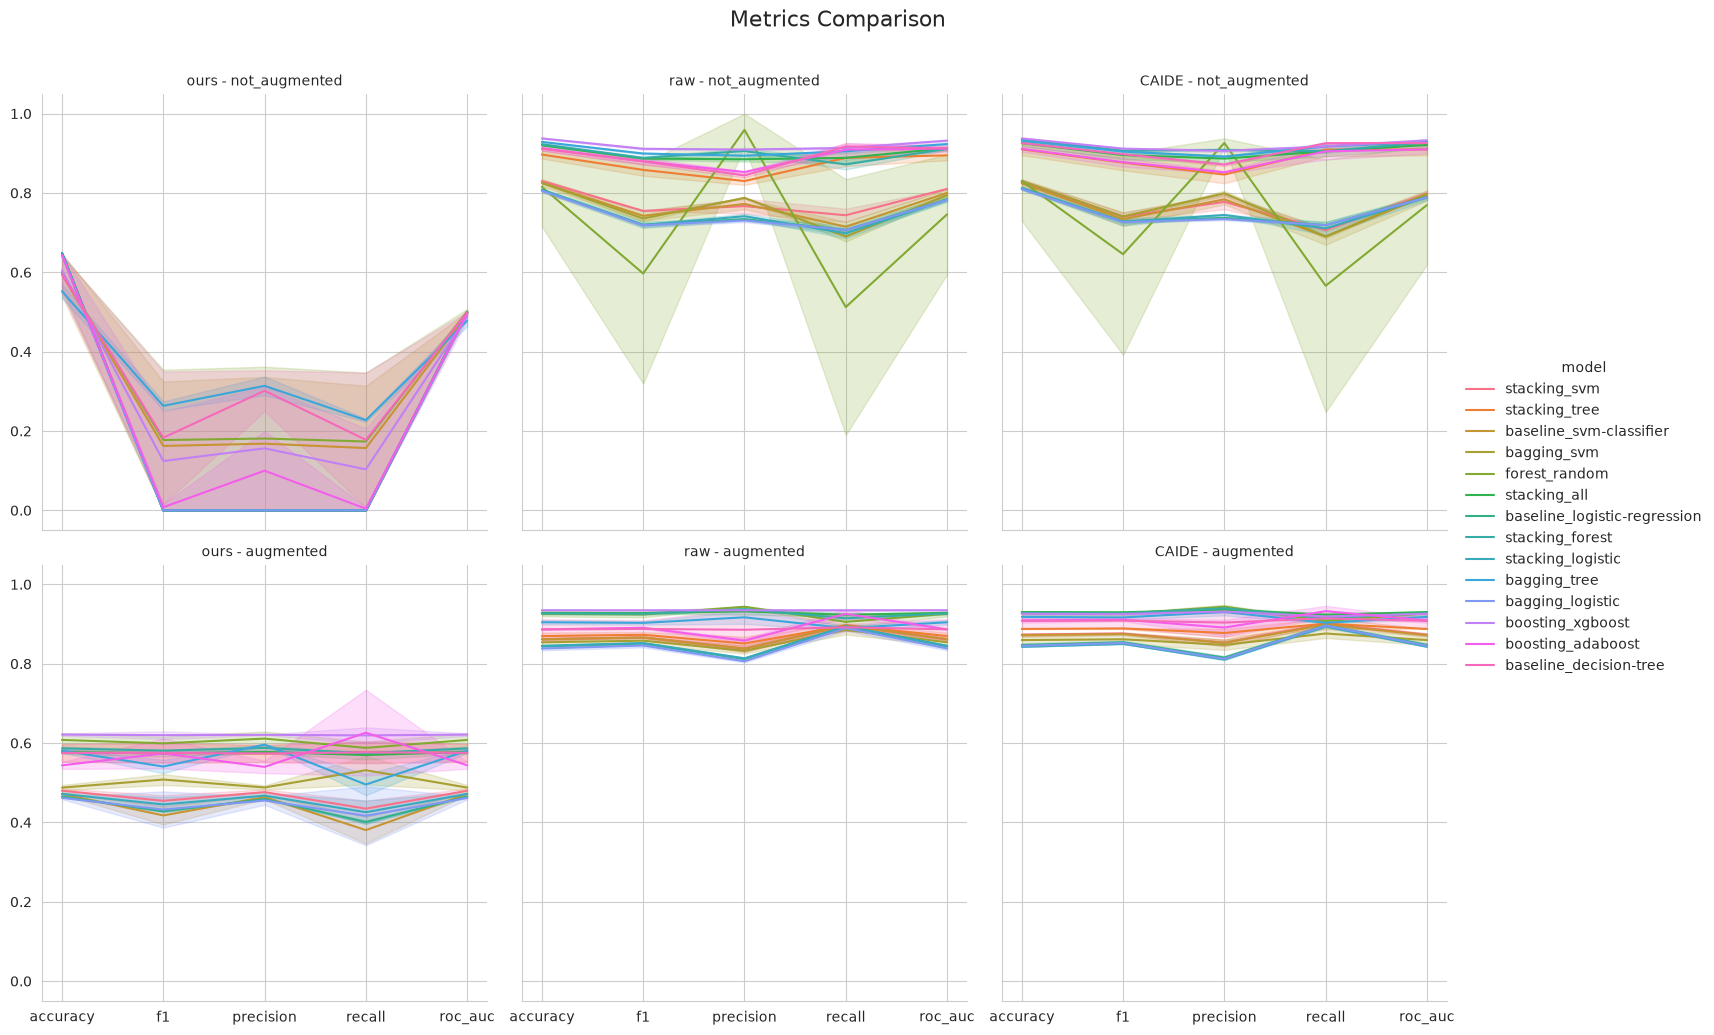

In [3]:
sns.set_style("whitegrid")
g = sns.relplot(
    kind='line',
    data=df_metrics_test,
    x='metric',
    y='value',
    hue='model',
    row='dataset_type',
    col='columns'
)
g.set_titles(template="{col_name} - {row_name}")
g.set_axis_labels("", "")
plt.suptitle('Metrics Comparison', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('comparison_metrics_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

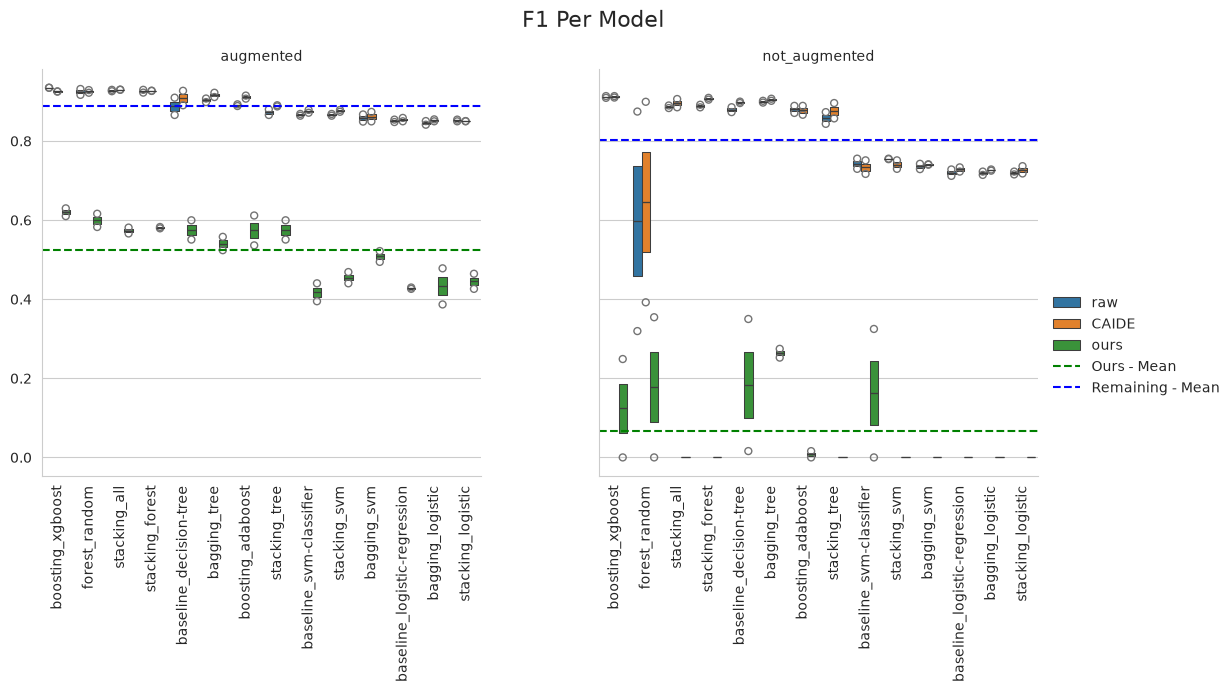

In [90]:
sns.set_style("whitegrid")
f1_data = df_metrics_test.loc[(df_metrics_test['metric'] == 'f1')].sort_values(by='value', ascending=False)
g = sns.catplot(
    kind="boxen", 
    data=f1_data, 
    x="model", 
    y='value',
    col='dataset_type',
    hue='columns')


not_agumented_ax = g.axes[0,1]
agumented_ax = g.axes[0,0]

not_agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] != 'ours')]['value'].mean(),
    linestyle='--', 
    color='blue',
)

not_agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'not_augmented')&(f1_data['columns'] == 'ours')]['value'].mean(),
    linestyle='--', 
    color='green',
)

agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] != 'ours')]['value'].mean(),
    linestyle='--', 
    color='blue',
)

agumented_ax.axhline(
    y=f1_data.loc[(f1_data['dataset_type'] == 'augmented')&(f1_data['columns'] == 'ours')]['value'].mean(),
    linestyle='--', 
    color='green',
)

g.set_xticklabels(rotation=90)
g.set_axis_labels('', '')
g.set_titles(template="{col_name}")

ours = plt.Line2D([0], [0], color='green', linestyle='--')
not_ours = plt.Line2D([0], [0], color='blue', linestyle='--')


g._legend_data['Ours - Mean'] = ours
g._legend_data['Remaining - Mean'] = not_ours
g._legend.remove()
g.add_legend()

plt.suptitle('F1 Per Model', y=1.05, fontsize=16)
plt.savefig(PLOTS_PATH('f1_per_model.png'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# get best params

#fig,ax = plt.subplots(2,3, figsize=(15,10))

table = """
<table>
<thead>
    <tr>
        <th>dataset</th>
        <th>columns</th>
        <th>eta</th>
        <th>gamma</th>
        <th>max_depth</th>
        <th>mean_precision_train</th>
        <th>mean_precision_test</th>
        <th>eval_precision</th>
        <th>mean_f1_train</th>
        <th>mean_f1_test</th>
        <th>eval_f1</th>
    </tr>
</thead>
</tbody>
"""


for i,dataset_type in enumerate(os.listdir(OUTPUTS_PATH)):
    for j,columns in enumerate(['ours', 'CAIDE', 'raw']):
        rf_params  = os.path.join(OUTPUTS_PATH, dataset_type, 'best-params', columns, 'boosting_xgboost', 'grid_search_output.csv')
        rf_output_metrics  = os.path.join(OUTPUTS_PATH, dataset_type, 'best-params', columns, 'boosting_xgboost', 'output_test_metrics.json')
        model_file = os.path.join(OUTPUTS_PATH, dataset_type, 'best-params', columns, 'boosting_xgboost', 'model.pkl')

        with open(model_file, "rb") as f:
            clf = load(f)
        
        print()
        print(f'dataset={dataset_type}; columns={columns}; model={clf}')

        eta = clf.learning_rate
        gamma = clf.gamma
        max_depth = clf.max_depth

        rf_params_df = pd.read_csv(rf_params)
        with open(rf_output_metrics, 'r') as file:
            metrics_output = json.load(file)
            precision_eval = metrics_output['precision']
            f1_eval = metrics_output['f1']

        #print(rf_params_df.loc[])
        
        print(list(filter(lambda x : 'param' in x, rf_params_df.columns.tolist())))
        print(f"eta = {eta}; gamma = {gamma}; max_depth = {max_depth}")
        model_data = rf_params_df.loc[
            (rf_params_df['param_eta'] == eta) & 
            (rf_params_df['param_gamma'] == gamma) &
            (rf_params_df['param_max_depth'] == max_depth )
        ]
        mean_precision_train = model_data['mean_train_precision'].item()
        mean_precision_test = model_data['mean_test_precision'].item()
        mean_f1_train = model_data['mean_train_f1'].item()
        mean_f1_test = model_data['mean_test_f1'].item()


        print(f'mean train precision =  {mean_precision_train}; mean test precision = {mean_precision_test}')
        print(f'mean train f1 =  {mean_f1_train}; mean test f1 = {mean_f1_test}')
        #sns.lineplot(data=rf_params_df, x=range(rf_params_df.shape[0]), y='mean_test_precision', ax=ax[i,j])
        #for s in range(5):
            #sns.lineplot(data=rf_params_df, x=range(rf_params_df.shape[0]), y=f'split{s}_test_precision', ax=ax[i,j])

        table += f"""
            <tr>    
                <td>{dataset_type}</td>
                <td>{columns}</td>
                <td>{eta}</td>
                <td>{gamma}</td>
                <td>{max_depth}</td>
                <td>{mean_precision_train}</td>
                <td>{mean_precision_test}</td>
                <td>{precision_eval}</td>
                <td>{mean_f1_train}</td>
                <td>{mean_f1_test}</td>
                <td>{f1_eval}</td>
            </tr>
        """
        
#plt.show()

table += "</tbody></table>"

display(HTML(table))


dataset=not_augmented; columns=ours; model=XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eta=0.1, eval_metric=None,
              feature_types=None, feature_weights=None, gamma=1,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None, ...)
['param_eta', 'param_gamma', 'param_max_depth', 'params']
eta = None; gamma = 1; max_depth = 6


KeyError: 'param_learning_rate'

In [ ]:
# use F1

# ROC AUC CURVE
# SHAP FOR RANDOM FOREST

# confusion matrices
# worse models
# WHY THIS BEST PARAM
# EVAL THE TEST FROM KAGGLE
# SUBMIT
# MAKE STREAM LIT